In [1]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Load the cleaned electricity dataset

from pathlib import Path

# Locate the processed dataset
file_path = Path("data/processed/household_power_clean.csv")

# Alternative path if notebook runs from notebooks folder
if not file_path.exists():
    file_path = Path("../data/processed/household_power_clean.csv")

# Check whether file exists
if not file_path.exists():
    raise FileNotFoundError("Cleaned dataset not found!")

# Load CSV using Pandas
df = pd.read_csv(file_path)

# Convert datetime column
df["datetime"] = pd.to_datetime(df["datetime"])

# Display dataset details
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five records
display(df.head())


Dataset loaded successfully!
Dataset shape: (34190, 10)


,datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Sub_metering_total,Unmetered
0,2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,626.0,3596.888889
1,2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,1415.0,2217.200000
2,2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,1087.0,2313.233333
3,2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,1007.0,2261.566667
4,2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,1058.0,1998.466667


In [3]:

# Step 3: Explore dataset information

print("DATASET INFORMATION")
print("-------------------")

df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())


DATASET INFORMATION
-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34190 entries, 0 to 34189
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   datetime               34190 non-null  datetime64[ns]
 1   Global_active_power    34190 non-null  float64       
 2   Global_reactive_power  34190 non-null  float64       
 3   Voltage                34190 non-null  float64       
 4   Global_intensity       34190 non-null  float64       
 5   Sub_metering_1         34190 non-null  float64       
 6   Sub_metering_2         34190 non-null  float64       
 7   Sub_metering_3         34190 non-null  float64       
 8   Sub_metering_total     34190 non-null  float64       
 9   Unmetered              34190 non-null  float64       
dtypes: datetime64[ns](1), float64(9)
memory usage: 2.6 MB

STATISTICAL SUMMARY


,datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Sub_metering_total,Unmetered
count,34190,34190.000000,34190.000000,34190.000000,34190.000000,34190.000000,34190.000000,34190.000000,34190.000000,34190.000000
mean,2008-12-02 04:50:16.987423232,1.091592,0.123733,240.839639,4.627658,67.245832,77.830681,387.106376,532.182890,559.408935
min,2006-12-16 17:00:00,0.124000,0.000000,225.834500,0.503333,0.000000,0.000000,0.000000,0.000000,82.766667
25%,2007-12-10 06:15:00,0.341975,0.078000,239.181500,1.513333,0.000000,0.000000,39.000000,54.000000,261.433333
50%,2008-11-30 09:30:00,0.802817,0.106933,240.978250,3.423333,0.000000,20.000000,99.000000,169.000000,345.500000
75%,2009-11-24 02:45:00,1.579250,0.149433,242.695583,6.606667,0.000000,39.000000,851.000000,1050.000000,666.991667
max,2010-11-26 21:00:00,6.560533,0.774333,251.902000,28.383333,2902.000000,2786.000000,1293.000000,4454.000000,3890.233333
std,NaN,0.897522,0.066854,3.001331,3.757348,212.195149,251.465480,440.912659,615.789407,496.914147



MISSING VALUES
datetime                 0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Sub_metering_total       0
Unmetered                0
dtype: int64


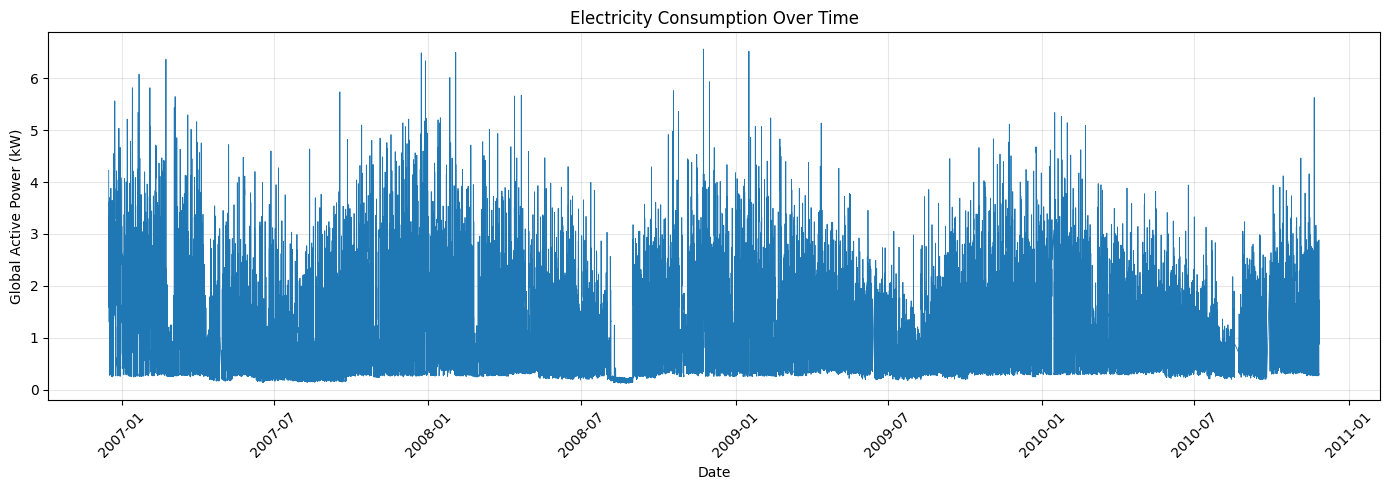

In [4]:

# Step 4: Electricity consumption over time

plt.figure(figsize=(14, 5))

plt.plot(
    df["datetime"],
    df["Global_active_power"],
    linewidth=0.6
)

plt.title("Electricity Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


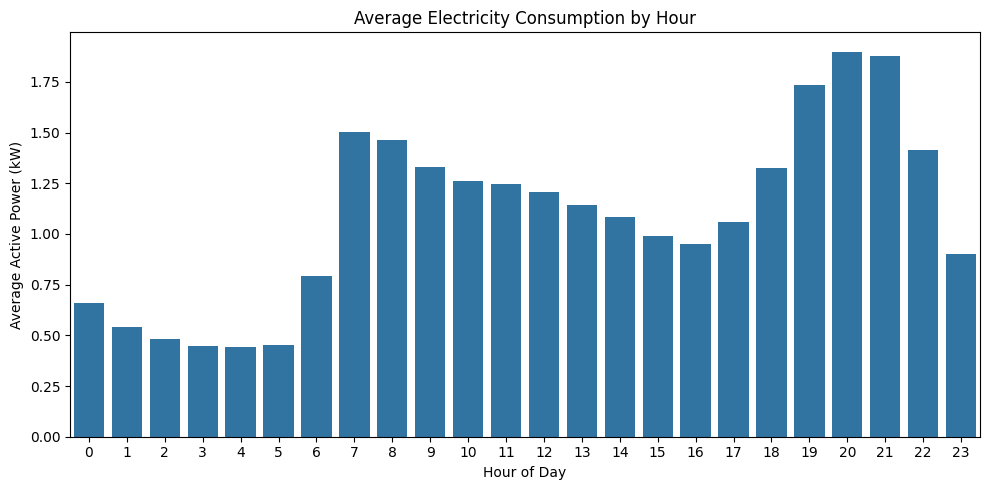

In [5]:

# Step 5: Average electricity consumption by hour

df["hour"] = df["datetime"].dt.hour

hourly_consumption = (
    df.groupby("hour")["Global_active_power"]
    .mean()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=hourly_consumption.index,
    y=hourly_consumption.values
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")

plt.tight_layout()
plt.show()


Average Electricity Consumption:
day_type
Weekday    1.035691
Weekend    1.233399
Name: Global_active_power, dtype: float64


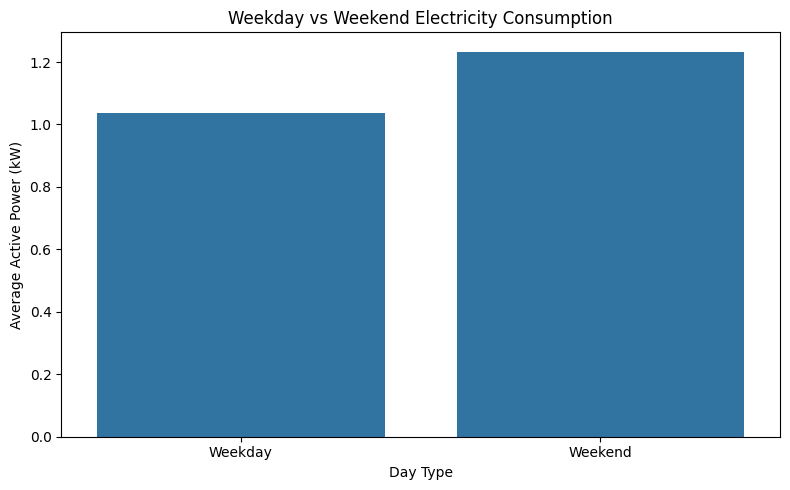

In [6]:

# Step 6: Weekday vs Weekend Consumption Analysis

# Extract day of week
# Monday = 0, Sunday = 6
df["day_of_week"] = df["datetime"].dt.dayofweek

# Create weekday/weekend column
df["day_type"] = df["day_of_week"].apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

# Calculate average electricity consumption
day_consumption = (
    df.groupby("day_type")["Global_active_power"]
    .mean()
)

print("Average Electricity Consumption:")
print(day_consumption)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=day_consumption.index,
    y=day_consumption.values
)

plt.title("Weekday vs Weekend Electricity Consumption")
plt.xlabel("Day Type")
plt.ylabel("Average Active Power (kW)")

plt.tight_layout()
plt.show()


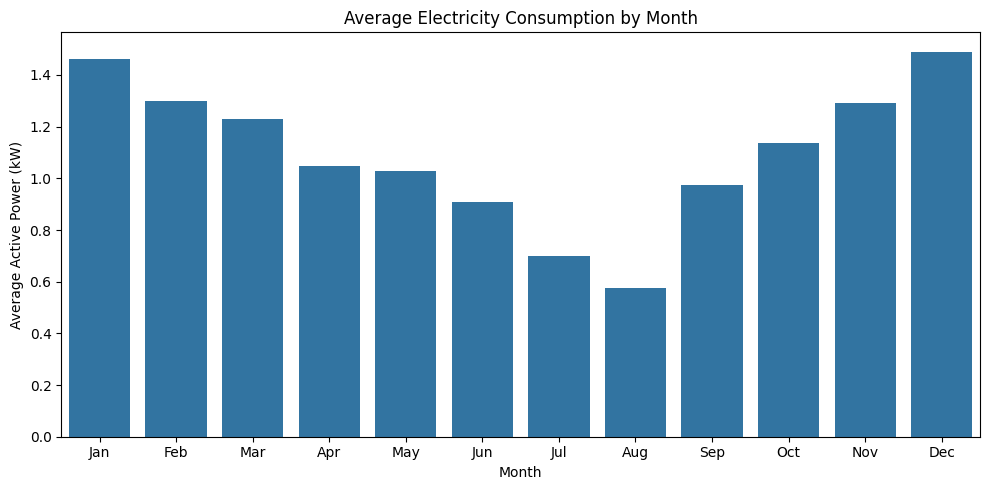

In [7]:

# Step 7: Monthly Electricity Consumption

df["month"] = df["datetime"].dt.month

monthly_consumption = (
    df.groupby("month")["Global_active_power"]
    .mean()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_consumption.index,
    y=monthly_consumption.values
)

plt.title("Average Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Active Power (kW)")

plt.xticks(
    ticks=range(12),
    labels=[
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.tight_layout()
plt.show()


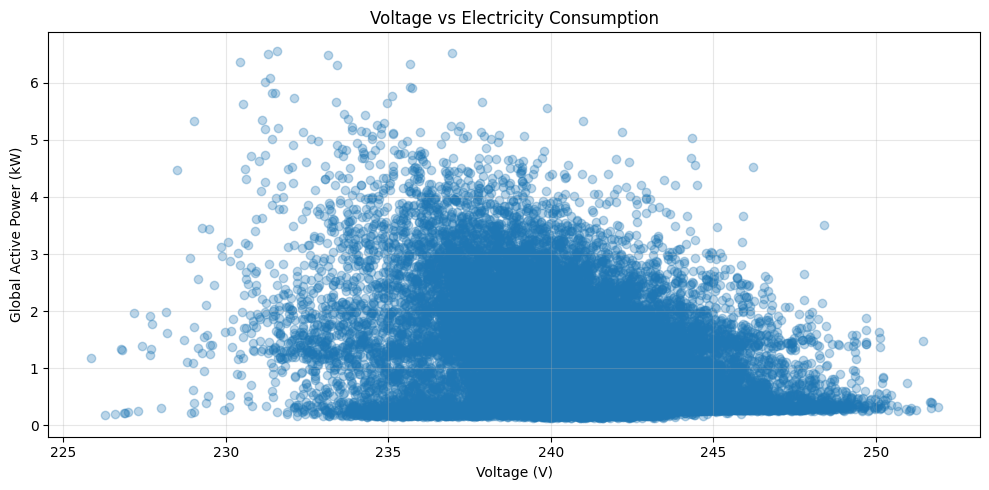

Voltage and Active Power Correlation: -0.3791406960083613


In [8]:

# Step 8: Voltage vs Electricity Consumption

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Voltage"],
    df["Global_active_power"],
    alpha=0.3
)

plt.title("Voltage vs Electricity Consumption")
plt.xlabel("Voltage (V)")
plt.ylabel("Global Active Power (kW)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = df["Voltage"].corr(
    df["Global_active_power"]
)

print("Voltage and Active Power Correlation:", correlation)


Average Sub-metering Consumption:
Kitchen               67.245832
Laundry               77.830681
Water Heater / AC    387.106376
dtype: float64


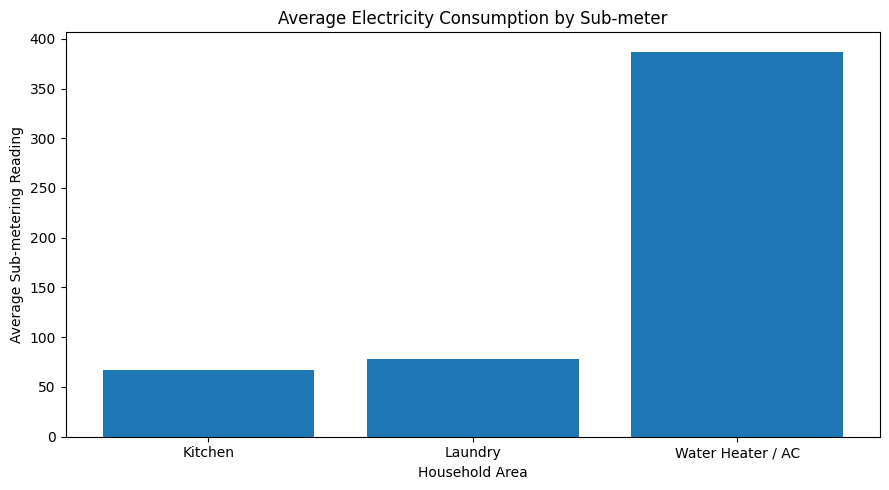

In [9]:

# Step 9: Sub-metering Analysis

submetering_data = {
    "Kitchen": df["Sub_metering_1"].mean(),
    "Laundry": df["Sub_metering_2"].mean(),
    "Water Heater / AC": df["Sub_metering_3"].mean()
}

submetering_df = pd.Series(submetering_data)

print("Average Sub-metering Consumption:")
print(submetering_df)

# Create visualization
plt.figure(figsize=(9, 5))

plt.bar(
    submetering_df.index,
    submetering_df.values
)

plt.title("Average Electricity Consumption by Sub-meter")
plt.xlabel("Household Area")
plt.ylabel("Average Sub-metering Reading")

plt.tight_layout()
plt.show()


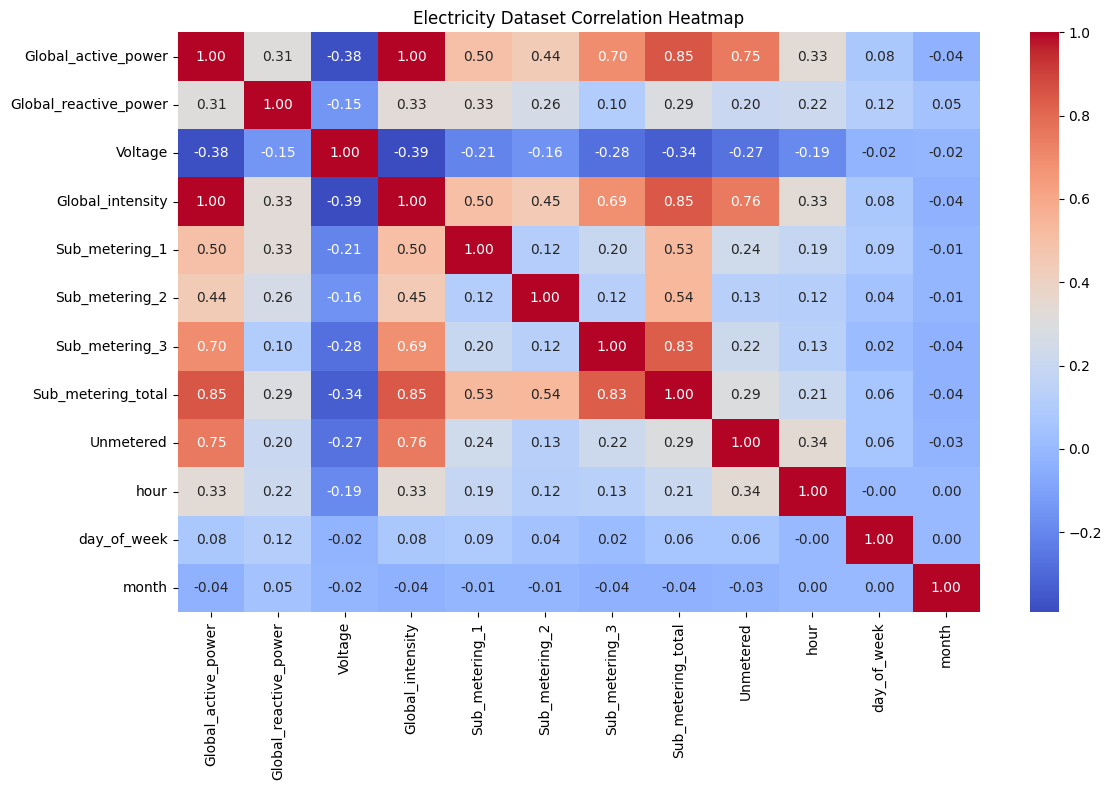

In [10]:

# Step 10: Correlation Heatmap

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Electricity Dataset Correlation Heatmap")

plt.tight_layout()
plt.show()
